In [1]:
import pandas as pd, matplotlib.pyplot as plt, os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
if os.path.basename(os.getcwd()) == 'for_exam': os.chdir('..')

In [2]:
df = pd.read_csv('data_exp1.csv')
le = LabelEncoder()
X, y = df.iloc[:, :-1], le.fit_transform(df.iloc[:, -1])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
num = X.select_dtypes('number').columns
pre = ColumnTransformer([('num', StandardScaler(), num), ('cat', OneHotEncoder(handle_unknown='ignore'), X.columns.difference(num))])


=== Decision Tree ===
              precision    recall  f1-score   support

     Dropout       0.72      0.67      0.69       427
    Enrolled       0.39      0.48      0.43       238
    Graduate       0.79      0.76      0.78       663

    accuracy                           0.68      1328
   macro avg       0.63      0.64      0.63      1328
weighted avg       0.70      0.68      0.69      1328


=== Logistic Regression ===
              precision    recall  f1-score   support

     Dropout       0.81      0.76      0.79       427
    Enrolled       0.55      0.37      0.44       238
    Graduate       0.80      0.93      0.86       663

    accuracy                           0.78      1328
   macro avg       0.72      0.69      0.70      1328
weighted avg       0.76      0.78      0.76      1328

Decision Tree          0.680723
Logistic Regression    0.775602
Name: Accuracy, dtype: float64


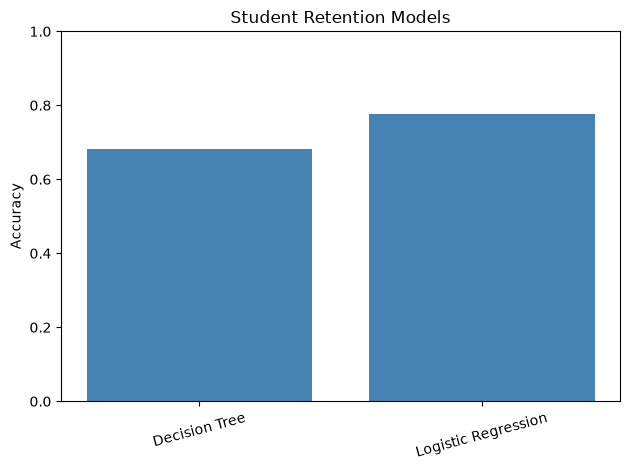

In [3]:
models = {'Decision Tree': DecisionTreeClassifier(random_state=42), 'Logistic Regression': LogisticRegression(max_iter=1000)}
acc = {}
for name, clf in models.items():
    pred = Pipeline([('pre', pre), ('clf', clf)]).fit(X_train, y_train).predict(X_test)
    acc[name] = accuracy_score(y_test, pred)
    print(f'\n=== {name} ===\n{classification_report(y_test, pred, target_names=le.classes_)}')

print(pd.Series(acc, name='Accuracy'))
plt.bar(list(acc), list(acc.values()), color='steelblue')
plt.ylim(0, 1); plt.ylabel('Accuracy'); plt.title('Student Retention Models')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()